# Threat Actor Analysis API — Gemini Colab prototype

## 1. System overview (README architecture)

External systems (for example a SIEM) send MITRE technique IDs to `POST /analyze`. The API validates the query, retrieves similar historical incidents from a vector index over the knowledge base, asks Gemini to attribute the top 3 groups **using only that retrieved evidence**, then returns structured JSON.

The knowledge base itself is the GitHub file `data/incidents_strict.json` (662 incidents derived from MITRE ATT&CK: `incident_id`, `group`, `techniques`, `description`).


## 2. Setup — packages, `GEMINI_API_KEY`, Knowledge Base

Install the Google Gen AI SDK (`google-genai`) plus FAISS (or numpy) for the vector index. Then read **`GEMINI_API_KEY` from Colab Secrets** (`google.colab.userdata`), with a graceful fallback when the secret is missing so the rest of the notebook still runs.

This matches the official Gemini Colab pattern: never hard-code the key; store it in the 🔑 Secrets panel as `GEMINI_API_KEY`.


In [12]:
import subprocess
import sys


def install_packages(packages):
    """Use %pip in IPython/Colab; fall back to python -m pip otherwise."""
    try:
        ipy = get_ipython()  # type: ignore[name-defined]
    except NameError:
        ipy = None
    if ipy is not None:
        ipy.run_line_magic("pip", "install " + " ".join(packages))
        return
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])


install_packages(
    [
        "google-genai>=1.0.0",
        "numpy",
        "scikit-learn",
        "pandas",
        "matplotlib",
        "fastapi",
        "uvicorn",
        "requests",
    ]
)
try:
    install_packages(["faiss-cpu"])
except Exception as exc:
    print("faiss-cpu could not be installed; numpy similarity will be used.", exc)

print("Package install step finished.")


Package install step finished.


### Read `GEMINI_API_KEY` (Colab Secret) without crashing

In Colab: Secrets → add `GEMINI_API_KEY` → enable notebook access.  
Outside Colab: the same name is read from the environment. If the key is absent, `HAS_GEMINI` is `False` and later Gemini cells **skip** instead of failing.


In [13]:
import os

GEMINI_API_KEY = None
IN_COLAB = False

try:
    from google.colab import userdata

    IN_COLAB = True
    try:
        GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
    except userdata.SecretNotFoundError:
        print("Colab Secret GEMINI_API_KEY was not found.")
        GEMINI_API_KEY = None
    except Exception as exc:
        print(f"Could not read Colab Secret GEMINI_API_KEY ({type(exc).__name__}: {exc}).")
        GEMINI_API_KEY = None
except ImportError:
    GEMINI_API_KEY = os.environ.get("GEMINI_API_KEY") or os.environ.get("GOOGLE_API_KEY")
    if not GEMINI_API_KEY:
        print("Not running in Colab and no GEMINI_API_KEY / GOOGLE_API_KEY env var.")

if isinstance(GEMINI_API_KEY, str):
    GEMINI_API_KEY = GEMINI_API_KEY.strip() or None

HAS_GEMINI = bool(GEMINI_API_KEY)
client = None

if HAS_GEMINI:
    from google import genai

    client = genai.Client(api_key=GEMINI_API_KEY)
    print("Gemini client ready (key loaded, value not printed).")
else:
    print("HAS_GEMINI = False — embeddings and generation will use the offline fallback.")

# Headless matplotlib when there is no display (local CI / this smoke run).
if not IN_COLAB and not os.environ.get("DISPLAY"):
    import matplotlib

    matplotlib.use("Agg")
    print("Matplotlib backend: Agg")


Gemini client ready (key loaded, value not printed).


### Load the Knowledge Base from GitHub (UML: GitHub Repository → DB)

The dataset is `data/incidents_strict.json` on branch `main` of this repo. We also load `prompts/prompt.json` (Gemini instructions) and `data/examples.json` (three homework inputs + the `y` JSON shape).

Shapes:

- **incident:** `incident_id`, `group`, `techniques`, `description`
- **prompt:** `system_prompt`, `user_prompt_template` with `{{techniques}}` and `{{incidents}}`
- **example:** `{ "X": { "techniques": [...] }, "y": { "groups": [...] } }`


In [31]:
import json
import urllib.request
from pathlib import Path

REPO_OWNER = "MadAcolyte"
REPO_NAME = "mitre-attack-threat-group-similarity"
REPO_BRANCH = "main"
RAW_BASE = f"https://raw.githubusercontent.com/{REPO_OWNER}/{REPO_NAME}/{REPO_BRANCH}"

INCIDENTS_PATH = "data/incidents_strict.json"
PROMPT_PATH = "prompts/prompt.json"
EXAMPLES_PATH = "data/examples.json"


def load_repo_json(relative_path: str):
    """Fetch JSON from the GitHub raw URL; use a local checkout if the network fails."""
    url = f"{RAW_BASE}/{relative_path}"
    request = urllib.request.Request(
        url,
        headers={"User-Agent": "threat-group-similarity-colab"},
    )
    try:
        with urllib.request.urlopen(request, timeout=60) as response:
            payload = json.loads(response.read().decode("utf-8"))
        print(f"Loaded {relative_path} from {url}")
        return payload
    except Exception as exc:
        local = Path(relative_path)
        if local.is_file():
            print(f"GitHub fetch failed for {relative_path} ({exc}); using local {local}.")
            return json.loads(local.read_text(encoding="utf-8"))
        raise RuntimeError(f"Could not load {relative_path} from GitHub or disk") from exc


incidents = load_repo_json(INCIDENTS_PATH)
prompt_spec = load_repo_json(PROMPT_PATH)
examples = load_repo_json(EXAMPLES_PATH)

assert isinstance(incidents, list) and incidents, "incidents_strict.json must be a non-empty list"
for key in ("incident_id", "group", "techniques", "description"):
    assert key in incidents[0], f"incident missing {key}"


Loaded data/incidents_strict.json from https://raw.githubusercontent.com/MadAcolyte/mitre-attack-threat-group-similarity/main/data/incidents_strict.json
Loaded prompts/prompt.json from https://raw.githubusercontent.com/MadAcolyte/mitre-attack-threat-group-similarity/main/prompts/prompt.json
Loaded data/examples.json from https://raw.githubusercontent.com/MadAcolyte/mitre-attack-threat-group-similarity/main/data/examples.json


## 3. Query Processor

The Query Processor is the first stage after `POST /analyze`. It:

1. **Validates** each token against `T\d{4}(\.\d{3})?` (for example `T1059` or `T1059.001`)
2. **Normalizes** whitespace and casing (`t1059.001` → `T1059.001`)
3. **Dedupes** while preserving order
4. **Warns** on IDs that are syntactically valid but **unknown to this dataset** (not present in any `incidents_strict.json` incident)

Invalid IDs are dropped, not sent to retrieval.


In [15]:
import re
from typing import Iterable

TECHNIQUE_RE = re.compile(r"^T\d{4}(\.\d{3})?$", re.IGNORECASE)

KNOWN_TECHNIQUES = {tid for incident in incidents for tid in incident["techniques"]}
print(f"Unique ATT&CK technique IDs in the knowledge base: {len(KNOWN_TECHNIQUES)}")


def normalize_technique_id(raw: str) -> str | None:
    if raw is None:
        return None
    token = str(raw).strip().upper()
    if not token:
        return None
    if TECHNIQUE_RE.fullmatch(token):
        return token
    return None


def process_query(raw_techniques: Iterable[str], known_ids: set[str] | None = None) -> dict:
    """Validate, normalize, dedupe, and flag unknown ATT&CK IDs."""
    known = known_ids if known_ids is not None else KNOWN_TECHNIQUES
    raw_list = list(raw_techniques)
    techniques: list[str] = []
    invalid: list[str] = []
    unknown: list[str] = []
    seen: set[str] = set()

    for raw in raw_list:
        normalized = normalize_technique_id(raw)
        if normalized is None:
            invalid.append(str(raw))
            continue
        if normalized in seen:
            continue
        seen.add(normalized)
        techniques.append(normalized)
        if normalized not in known:
            unknown.append(normalized)

    if invalid:
        print("WARNING: dropped invalid technique IDs:", invalid)
    if unknown:
        print("WARNING: technique IDs not present in incidents_strict.json:", unknown)
    if not techniques:
        print("WARNING: query has no valid technique IDs after validation.")

    return {
        "techniques": techniques,
        "invalid": invalid,
        "unknown": unknown,
        "dropped_duplicates": max(0, len(raw_list) - len(invalid) - len(techniques)),
    }


print("\nQuery Processor demo:")
demo_query = process_query(
    [
        " t1059.001 ",
        "T1059.001",
        "T1071.001",
        "T1105",
        "T105",
        "not-a-technique",
        "T9999.001",
    ]
)
print(json.dumps(demo_query, indent=2))


Unique ATT&CK technique IDs in the knowledge base: 511

Query Processor demo:
{
  "techniques": [
    "T1059.001",
    "T1071.001",
    "T1105",
    "T9999.001"
  ],
  "invalid": [
    "T105",
    "not-a-technique"
  ],
  "unknown": [
    "T9999.001"
  ],
  "dropped_duplicates": 1
}


## 4. Jaccard Index

The index stores the normalized technique set of each knowledge-base incident. There are no embeddings, FAISS, TF-IDF, or API calls at this step.

- **Query:** the validated technique IDs from the Query Processor.
- **Score:** Jaccard similarity between the query set and each incident's technique set: `|query ∩ incident| / |query ∪ incident|`, from 0 (no shared techniques) to 1 (identical sets).
- **Ranking:** incidents are sorted by Jaccard, with raw overlap count as the tiebreaker.

Matching is exact and deterministic: the same query always returns the same incidents, and it works without an API key.

In [25]:
import re
from typing import Iterable


def normalize_techniques(techniques: Iterable[str]) -> list[str]:
    if isinstance(techniques, str):
        raise ValueError("techniques must be a list of IDs, not one string.")
    result = set()
    for value in techniques:
        if not isinstance(value, str):
            raise ValueError("Every technique ID must be a string.")
        value = value.strip().upper()
        if not re.fullmatch(r"T\d{4}(?:\.\d{3})?", value):
            raise ValueError(f"Invalid technique ID format: {value!r}")
        result.add(value)
    return sorted(result)


def jaccard(a: Iterable[str], b: Iterable[str]) -> float:
    sa, sb = set(a), set(b)
    return len(sa & sb) / len(sa | sb) if sa | sb else 0.0


class VectorIndex:
    """Jaccard similarity over technique sets (no embeddings)."""

    def __init__(self, incidents: list[dict]):
        if not incidents:
            raise ValueError("incidents cannot be empty.")
        self.incidents = []
        for incident in incidents:
            item = dict(incident)
            item["techniques"] = normalize_techniques(item["techniques"])
            if not item["techniques"]:
                raise ValueError("Each incident must contain at least one technique.")
            self.incidents.append(item)
        self._sets = [set(i["techniques"]) for i in self.incidents]
        self.backend = "jaccard"

    def build(self) -> None:
        pass  # nothing to build; kept so existing calls still work

    def search(self, techniques: list[str], k: int = 8) -> list[tuple[int, float]]:
        query = set(normalize_techniques(techniques))
        if not query:
            raise ValueError("At least one technique is required.")
        if k <= 0:
            return []
        scored = []
        for idx, inc in enumerate(self._sets):
            overlap = len(query & inc)
            scored.append((idx, overlap / len(query | inc), overlap))
        # Jaccard first, raw overlap as tiebreaker
        scored.sort(key=lambda r: (r[1], r[2]), reverse=True)
        return [(idx, float(j)) for idx, j, _ in scored[:k]]


if __name__ == "__main__":
    if "incidents" not in globals():
        raise RuntimeError("Load incidents before executing this cell/file.")
    vector_index = VectorIndex(incidents)
    vector_index.build()
    print("Vector Index backend:", vector_index.backend)

Vector Index backend: jaccard


## 5. RAG Retriever

The retriever asks the Jaccard Index for the incidents most similar to the query, then returns **group + techniques + description** for each, along with the similarity score and the number of overlapping techniques (the UML `Index → RAG → DB → RAG` path).

Returned rows are the context that the Gemini step is allowed to use. The system prompt forbids inventing actors or techniques that are not in this list.

In [26]:
DEFAULT_TOP_K = 8


class RAGRetriever:
    def __init__(self, index: VectorIndex, knowledge_base: list[dict]):
        self.index = index
        self.knowledge_base = knowledge_base

    def retrieve(self, techniques: list[str], k: int = DEFAULT_TOP_K) -> list[dict]:
        if not techniques:
            return []

        query = set(normalize_techniques(techniques))
        results = []
        for idx, score in self.index.search(techniques, k=k):
            incident = self.index.incidents[idx]  # normalized techniques
            results.append(
                {
                    "score": round(score, 4),  # = jaccard
                    "overlap": len(query & set(incident["techniques"])),
                    "incident_id": incident["incident_id"],
                    "group": incident["group"],
                    "techniques": list(incident["techniques"]),
                    "description": incident["description"],
                    "incident": incident,
                }
            )
        return results


retriever = RAGRetriever(vector_index, incidents)

print("RAG demo on the first examples.json query:")
rag_demo_query = process_query(examples[0]["X"]["techniques"])
rag_demo_hits = retriever.retrieve(rag_demo_query["techniques"], k=5)
for hit in rag_demo_hits:
    print(
        f"  score={hit['score']:.4f}  {hit['incident_id']:20s}  "
        f"{hit['group']:20s}  overlap={hit['overlap']}"
    )

RAG demo on the first examples.json query:
  score=1.0000  ATTACK-G1057-R002     ShinyHunters          overlap=11
  score=0.1765  ATTACK-G1057-R001     ShinyHunters          overlap=3
  score=0.1667  ATTACK-G1057-R003     ShinyHunters          overlap=3
  score=0.1538  ATTACK-G0028-R001     Threat Group-1314     overlap=2
  score=0.1538  ATTACK-G1055-R005     VOID MANTICORE        overlap=2


## 6. Gemini API

This component fills `prompts/prompt.json`:

- `system_prompt` — analyst instructions: use **only** retrieved incidents; reconstruct an attack chain only when the evidence supports it
- `user_prompt_template` — placeholders `{{techniques}}` and `{{incidents}}`

Gemini is asked for **JSON only**, matching the `y` object in `data/examples.json`:

```json
{
  "groups": [
    {
      "name": "string",
      "match_percentage": 0,
      "matching_techniques": [],
      "similar_incidents": [
        {
          "incident_id": "string",
          "missing_techniques": [],
          "description": "string"
        }
      ],
      "reasoning": "string"
    }
  ]
}
```

The prompt asks for the **top 3 groups**. `examples.json` itself is a *shape* illustration (toy `INC-001` / APT28 rows); live answers come from `incidents_strict.json`.


In [27]:
GENERATION_MODEL = "gemini-3.5-flash-lite"


def format_incidents_for_prompt(retrieved: list[dict]) -> str:
    blocks = []
    for hit in retrieved:
        inc = hit["incident"]
        blocks.append(
            "\n".join(
                [
                    f"- incident_id: {inc['incident_id']}",
                    f"  group: {inc['group']}",
                    f"  jaccard_similarity: {hit['score']}",
                    f"  techniques: {', '.join(inc['techniques'])}",
                    f"  description: {inc['description']}",
                ]
            )
        )
    return "\n".join(blocks) if blocks else "(no incidents retrieved)"


def build_user_prompt(techniques: list[str], retrieved: list[dict]) -> str:
    template = prompt_spec["user_prompt_template"]
    return (
        template.replace("{{techniques}}", json.dumps(techniques, ensure_ascii=False))
        .replace("{{incidents}}", format_incidents_for_prompt(retrieved))
    )


def generate_with_gemini(techniques: list[str], retrieved: list[dict]) -> str:
    """Call Gemini and return raw JSON text. Raises on failure."""
    if not HAS_GEMINI or client is None:
        raise RuntimeError("Gemini client is not available (missing GEMINI_API_KEY).")

    from google.genai import types

    response = client.models.generate_content(
        model=GENERATION_MODEL,
        contents=build_user_prompt(techniques, retrieved),
        config=types.GenerateContentConfig(
            system_instruction=prompt_spec["system_prompt"],
            response_mime_type="application/json",
            temperature=0.2,
        ),
    )
    return response.text

## 7. Result Generator

Parse the model JSON (strip markdown fences if needed) and return it as plain JSON with a `groups` array in the `y` shape, capped at 3 groups. Any failure (API error, invalid JSON) raises instead of falling back.

Each group contains:

- `match_percentage`: how well the group matches the query, as judged by Gemini from the retrieved incidents
- `matching_techniques`: techniques shared with the query
- `similar_incidents[].missing_techniques`: techniques in the historical incident **not** in the query
- `reasoning`: cites concrete incident IDs (the prompt forbids generic "commonly associated" language)

In [28]:
import json
import re


def parse_model_json(text: str) -> dict:
    cleaned = text.strip()
    cleaned = re.sub(r"^```(?:json)?\s*", "", cleaned)
    cleaned = re.sub(r"\s*```$", "", cleaned)
    payload = json.loads(cleaned)
    if not isinstance(payload, dict) or not isinstance(payload.get("groups"), list):
        raise ValueError("model output must be an object with a 'groups' list")
    payload["groups"] = payload["groups"][:3]
    return payload


def generate_result(techniques: list[str], retrieved: list[dict]) -> dict:
    gemini_text = generate_with_gemini(techniques, retrieved)
    return parse_model_json(gemini_text)


demo_payload = generate_result(rag_demo_query["techniques"], rag_demo_hits)
print(json.dumps(demo_payload, indent=2))

{
  "groups": [
    {
      "name": "ShinyHunters",
      "match_percentage": 100,
      "matching_techniques": [
        "T1072",
        "T1078.002",
        "T1078.004",
        "T1210",
        "T1528",
        "T1530",
        "T1580",
        "T1593.003",
        "T1595.002",
        "T1598.003",
        "T1657"
      ],
      "similar_incidents": [
        {
          "incident_id": "ATTACK-G1057-R002",
          "missing_techniques": [],
          "description": "ShinyHunters activity reported in 'Dark Web Profile: ShinyHunters' (2024). Observed procedures include: ShinyHunters has collected data from insecure cloud buckets; ShinyHunters has used spearphishing emails with malicious links to gain initial access and credentials; ShinyHunters has stolen valid OAuth credentials from DevOps personnel or a company GitHub repository; ShinyHunters has used valid cloud accounts to gain initial access or to escalate privileges within cloud environments."
        },
        {
          "i

## 8. REST API: `POST /analyze`

`analyze(techniques)` is the function the UML REST API would call. It wires Query Processor → RAG Retriever → Gemini API → Result Generator and returns JSON with a `groups` array in the `y` shape, plus diagnostics (invalid/unknown IDs, retrieved incident IDs).

The optional FastAPI app below is started in a **background thread** (Colab-friendly) and called once with `requests` to show the HTTP contract:

```http
POST /analyze
Content-Type: application/json

{"techniques": ["T1059.001", "T1071.001", "T1105"]}
```

In [29]:
def analyze(techniques, k: int = DEFAULT_TOP_K, top_groups: int = 3) -> dict:
    """End-to-end Threat Actor Analysis API (the POST /analyze handler)."""
    query = process_query(techniques)
    retrieved = retriever.retrieve(query["techniques"], k=k)
    payload = generate_result(query["techniques"], retrieved)
    payload["groups"] = payload["groups"][:top_groups]
    payload["validated_techniques"] = query["techniques"]
    payload["invalid_techniques"] = query["invalid"]
    payload["unknown_techniques"] = query["unknown"]
    payload["retrieved_incident_ids"] = [hit["incident_id"] for hit in retrieved]
    return payload


api_demo = analyze(examples[0]["X"]["techniques"])
print("analyze() keys:", sorted(api_demo.keys()))
print("groups:", [g["name"] for g in api_demo["groups"]])

analyze() keys: ['groups', 'invalid_techniques', 'retrieved_incident_ids', 'unknown_techniques', 'validated_techniques']
groups: ['ShinyHunters', 'TeamPCP', 'Storm-0501']


## 9. End-to-end run of `data/examples.json`

Each example has `X.techniques` (the API input) and `y` (the required output shape, not a gold label for `incidents_strict.json`). We run `analyze(X.techniques)` for all three queries, print the JSON, and plot the match percentages.

Path: input technique IDs → Query Processor → Jaccard retrieval (RAG) → Gemini → `groups` JSON → chart.


Example 1/3  X.techniques = ['T1072', 'T1078.002', 'T1078.004', 'T1210', 'T1528', 'T1530', 'T1580', 'T1593.003', 'T1595.002']
validated: ['T1072', 'T1078.002', 'T1078.004', 'T1210', 'T1528', 'T1530', 'T1580', 'T1593.003', 'T1595.002']
retrieved: ['ATTACK-G1057-R002', 'ATTACK-G0028-R001', 'ATTACK-G1055-R005', 'ATTACK-G0035-R003', 'ATTACK-G1056-R002', 'ATTACK-G1057-R001', 'ATTACK-G1056-R013', 'ATTACK-G1057-R003']
{
  "groups": [
    {
      "name": "ShinyHunters",
      "match_percentage": 81,
      "matching_techniques": [
        "T1072",
        "T1078.002",
        "T1078.004",
        "T1210",
        "T1528",
        "T1530",
        "T1580",
        "T1593.003",
        "T1595.002"
      ],
      "similar_incidents": [
        {
          "incident_id": "ATTACK-G1057-R002",
          "missing_techniques": [
            "T1598.003",
            "T1657"
          ],
          "description": "ShinyHunters activity reported in \"Dark Web Profile: ShinyHunters\" (2024). Observed proce

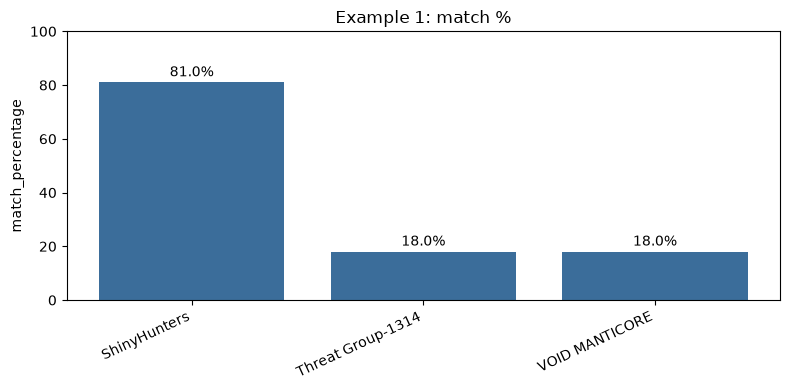


Example 2/3  X.techniques = ['T1059.001', 'T1566.001', 'T1071.001']
validated: ['T1059.001', 'T1566.001', 'T1071.001']
retrieved: ['ATTACK-G0079-R001', 'ATTACK-G0100-R003', 'ATTACK-G0016-R001', 'ATTACK-G0102-R006', 'ATTACK-G0049-R008', 'ATTACK-G0062-R001', 'ATTACK-G0079-R002', 'ATTACK-G0081-R004']
{
  "groups": [
    {
      "name": "Inception",
      "match_percentage": 43,
      "matching_techniques": [
        "T1059.001",
        "T1071.001",
        "T1566.001"
      ],
      "similar_incidents": [
        {
          "incident_id": "ATTACK-G0100-R003",
          "missing_techniques": [
            "T1059.005",
            "T1203",
            "T1204.002",
            "T1221"
          ],
          "description": "Inception activity reported in 'Inception Attackers Target Europe with Year-old Office Vulnerability' (2018). Observed procedures include: Inception has used weaponized documents attached to spearphishing emails for reconnaissance and initial compromise; Inception has u

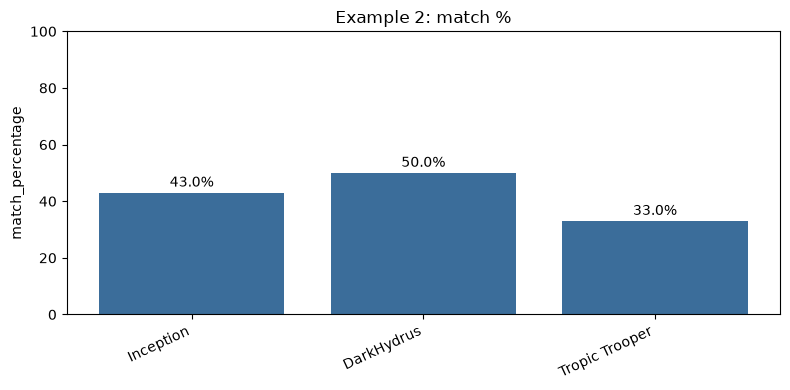


Example 3/3  X.techniques = ['T1547.001', 'T1053.005']
validated: ['T1547.001', 'T1053.005']
retrieved: ['ATTACK-G0051-R001', 'ATTACK-G0019-R002', 'ATTACK-G0046-R001', 'ATTACK-G0010-R009', 'ATTACK-G0046-R002', 'ATTACK-G0048-R001', 'ATTACK-G0022-R003', 'ATTACK-G0069-R001']
{
  "groups": [
    {
      "name": "FIN10",
      "match_percentage": 66,
      "matching_techniques": [
        "T1053.005",
        "T1547.001"
      ],
      "similar_incidents": [
        {
          "incident_id": "ATTACK-G0051-R001",
          "missing_techniques": [
            "T1059.001"
          ],
          "description": "FIN10 activity reported in \"Github PowerShellEmpire\". Observed procedures include: FIN10 has established persistence by using the Registry option in PowerShell Empire to add a Run key; FIN10 has established persistence by using S4U tasks as well as the Scheduled Task option in PowerShell Empire; FIN10 uses PowerShell for execution as well as PowerShell Empire to establish persistence

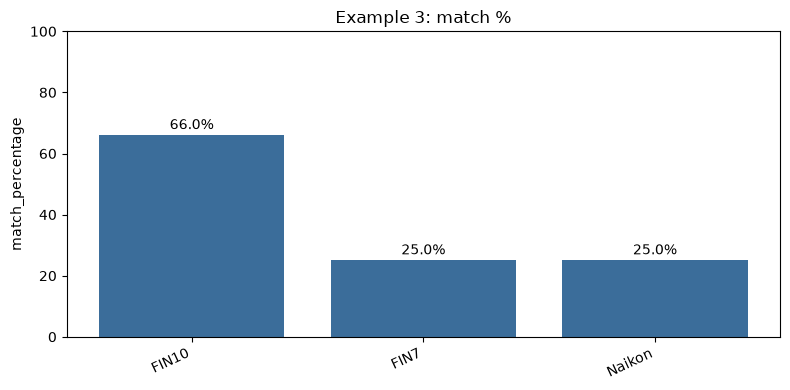


All 3 examples finished.


In [33]:
import json
import matplotlib.pyplot as plt


def plot_groups(result: dict, title: str) -> None:
    groups = result["groups"]
    if not groups:
        print("No groups to plot.")
        return
    names = [g["name"] for g in groups]
    pcts = [g["match_percentage"] for g in groups]

    fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.bar(names, pcts, color="#3b6d9a")
    ax.bar_label(bars, fmt="%.1f%%", padding=2)
    ax.set_ylim(0, 100)
    ax.set_ylabel("match_percentage")
    ax.set_title(title)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()


e2e_results = []
for i, example in enumerate(examples, start=1):
    x_techs = example["X"]["techniques"]
    print("\n" + "=" * 72)
    print(f"Example {i}/{len(examples)}  X.techniques = {x_techs}")
    result = analyze(x_techs)
    e2e_results.append(result)
    print("validated:", result["validated_techniques"])
    print("retrieved:", result["retrieved_incident_ids"])
    print(json.dumps({"groups": result["groups"]}, indent=2))
    plot_groups(result, title=f"Example {i}: match %")

print("\nAll", len(e2e_results), "examples finished.")

- Dataset copyright: © 2026 The MITRE Corporation. See the repository README.
